# Training pipeline: which Valencia Airbnb listings will leave the platform?

This notebook runs start to finish with `uv run python main.py train`. It:

1. loads three quarterly Inside Airbnb snapshots of Valencia (March, June/July and September 2026),
2. builds the target (did the listing disappear by the next snapshot?),
3. engineers features from each listing **as it looked at the start of the quarter**,
4. splits by time: train on March → July, test on July → September,
5. trains the same logistic regression three ways (scikit-learn, a manual PyTorch loop, `nn.Module` + `torch.optim`),
6. compares them with each other and with a naive baseline,
7. picks the decision threshold that minimises business cost on validation data,
8. saves everything the dashboard (`app.py`) needs, so the app never retrains.

The business assumptions (call cost, save rate, value of a lost host) live in `churn_model.py`, shared with the dashboard.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from churn_model import (CALL_COST, SAVE_RATE, VALUE_LOST, LogisticRegressionModule,
                         business_cost, manual_predict_proba)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA = Path("data")
MODELS = Path("models")
ARTIFACTS = Path("artifacts")
MODELS.mkdir(exist_ok=True)
ARTIFACTS.mkdir(exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 1. Load the three snapshots

Each file is one quarterly scrape of every Valencia listing. One row = one listing on the scrape date.

In [2]:
snapshots = {
    "mar": pd.read_csv(DATA / "listings_2026-03-28.csv.gz", low_memory=False),
    "jul": pd.read_csv(DATA / "listings_2026-06-26.csv.gz", low_memory=False),
    "sep": pd.read_csv(DATA / "listings_2026-09-20.csv.gz", low_memory=False),
}
for name, df in snapshots.items():
    print(f"{name}: {df.shape[0]:,} listings, {df.shape[1]} columns, scraped {df['last_scraped'].min()} to {df['last_scraped'].max()}")

mar: 4,930 listings, 90 columns, scraped 2026-03-28 to 2026-03-28
jul: 7,851 listings, 90 columns, scraped 2026-06-26 to 2026-07-03
sep: 7,968 listings, 90 columns, scraped 2026-09-25 to 2026-09-25


## 2. Build the target

A listing **left** (target = 1) if it is in one snapshot and missing from the next. It **stayed** (target = 0) if it is in both.

Only **short-stay listings** (minimum stay of 7 nights or less) are kept, in both periods. The reason is a data problem found while exploring, explained just below.

This gives two periods:
- **March → July**: features from March, outcome = gone by July (used for training and validation)
- **July → September**: features from July, outcome = gone by September (used only for the final test)

In [3]:
MAX_MIN_NIGHTS = 7  # short-stay listings only (see the next section for why)


def build_period(start: pd.DataFrame, end: pd.DataFrame) -> pd.DataFrame:
    period = start[start["minimum_nights"] <= MAX_MIN_NIGHTS].copy()
    period["left"] = (~period["id"].isin(end["id"])).astype(int)
    return period

train_period = build_period(snapshots["mar"], snapshots["jul"])
test_period = build_period(snapshots["jul"], snapshots["sep"])

for name, p in [("March -> July", train_period), ("July -> September", test_period)]:
    print(f"{name}: {len(p):,} listings, {p['left'].sum():,} left ({p['left'].mean():.1%})")

March -> July: 4,923 listings, 307 left (6.2%)
July -> September: 5,501 listings, 353 left (6.4%)


### Data quality checks that shaped the features

Some columns that look useful cannot be used, because they are empty in the **March** snapshot (our training data). A feature only works if it exists both when the model learns and when it is used.

In [4]:
check_cols = ["host_since", "price", "estimated_revenue_l365d", "host_response_rate",
              "instant_bookable", "license", "review_scores_rating", "bedrooms"]
quality = pd.DataFrame({name: df[check_cols].notna().mean().round(2) for name, df in snapshots.items()})
print("Share of rows filled in, per snapshot:")
print(quality)

print("\nListings by minimum stay, per snapshot:")
for name, df in snapshots.items():
    print(f"  {name}: {(df['minimum_nights'] <= 7).sum():,} with 7 nights or less, "
          f"{(df['minimum_nights'] > 7).sum():,} with more than 7 (longest minimum: {df['minimum_nights'].max():.0f})")

Share of rows filled in, per snapshot:
                          mar   jul   sep
host_since               0.00  0.00  0.00
price                    0.00  0.93  0.90
estimated_revenue_l365d  0.00  0.93  0.90
host_response_rate       0.00  0.00  0.00
instant_bookable         0.00  0.00  0.00
license                  0.77  0.81  0.64
review_scores_rating     0.92  0.88  0.90
bedrooms                 0.99  0.81  1.00

Listings by minimum stay, per snapshot:
  mar: 4,923 with 7 nights or less, 0 with more than 7 (longest minimum: 7)
  jul: 5,501 with 7 nights or less, 2,347 with more than 7 (longest minimum: 366)
  sep: 4,384 with 7 nights or less, 2,277 with more than 7 (longest minimum: 366)


- `host_since`, `host_response_rate` and `instant_bookable` are empty everywhere, so they are dropped.
- `price` and `estimated_revenue_l365d` are empty in March only. Using them would mean training on a column full of blanks, so they are left out of the model. This is also why the business cost uses one average value per lost host (`VALUE_LOST` in `churn_model.py`) instead of each listing's own revenue.
- **The March scrape only covers listings with a minimum stay of 7 nights or less**, while July and September also include about 2,300 listings that require longer stays (monthly and mid term rentals). That is why March has about 3,000 fewer listings, not seasonal growth as it first looked. A model trained only on short-stay listings should not be tested on long-stay ones, so both periods are limited to short-stay listings. This also matches the business case: short tourist stays are where the platform earns most of its commission.
- Host experience comes from `hosts_time_as_host_years` and `hosts_time_as_host_months`, which together replace `host_since`.

## 3. Feature engineering

Everything is computed from the listing **as it was at the start of the period**, never from the later snapshot. Each feature has a business reason:

| Feature | Built from | Why it might predict leaving |
|---|---|---|
| `room_group` | `room_type` | Private rooms are often casual hosts renting a spare room |
| `accommodates`, `bedrooms`, `bathrooms`, `shared_bath` | size columns; `bathrooms_text` parsed from text like "1.5 shared baths" | Bigger, self contained homes are usually more professional |
| `n_amenities` | `amenities` (a text list) | More effort put into the listing |
| `has_license`, `regional_license` | `license` text | Valencia requires a tourist flat registration; unregistered listings are at risk of being removed |
| `superhost`, `identity_verified` | t/f columns | Committed hosts |
| `host_tenure_months` | years + months on the platform | New hosts may not stay |
| `log_host_listings` | `calculated_host_listings_count` | Professional managers with many listings behave differently from one apartment owners |
| `avail_30_share`, `avail_365_share` | availability columns | A calendar that is fully blocked or fully open can mean the host has stopped |
| `occupancy_share` | `estimated_occupancy_l365d` | Listings that get booked earn money and have a reason to stay |
| `log_reviews`, `log_reviews_ltm`, `reviews_l30d` | review counts | Recent activity |
| `has_reviews`, `log_days_since_last_review` | `last_review` date | A long silence suggests an inactive listing |
| `listing_age_years` | `first_review` date | Older listings have survived longer |
| `rating` | `review_scores_rating` | Guest satisfaction |
| `log_min_nights` | `minimum_nights` | Hosts asking for longer minimum stays are moving away from pure tourist rentals |
| `distance_km` | latitude and longitude | Distance to the city centre (Plaza del Ayuntamiento) |
| `district` | `neighbourhood_group_cleansed` | Area effects not captured by distance |

In [5]:
CENTRE_LAT, CENTRE_LON = 39.4699, -0.3763  # Plaza del Ayuntamiento, Valencia


def parse_bathrooms(text):
    if pd.isna(text):
        return np.nan
    text = str(text).lower()
    if "half" in text and not any(ch.isdigit() for ch in text):
        return 0.5
    try:
        return float(text.split()[0])
    except ValueError:
        return np.nan


def haversine_km(lat, lon, lat0=CENTRE_LAT, lon0=CENTRE_LON):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    snapshot_date = pd.to_datetime(df["last_scraped"])
    last_review = pd.to_datetime(df["last_review"])
    first_review = pd.to_datetime(df["first_review"])
    flag = lambda col: (df[col] == "t").astype(int)

    f = pd.DataFrame(index=df.index)
    f["room_group"] = df["room_type"].map({"Entire home/apt": "entire", "Private room": "private"}).fillna("other")
    f["accommodates"] = df["accommodates"]
    f["bedrooms"] = df["bedrooms"]
    f["bathrooms"] = df["bathrooms_text"].map(parse_bathrooms)
    f["shared_bath"] = df["bathrooms_text"].str.contains("shared", case=False, na=False).astype(int)
    f["n_amenities"] = df["amenities"].map(lambda s: len(json.loads(s)) if isinstance(s, str) else 0)
    f["has_license"] = df["license"].notna().astype(int)
    f["regional_license"] = df["license"].str.contains("Regional", na=False).astype(int)
    f["superhost"] = flag("host_is_superhost")
    f["identity_verified"] = flag("host_identity_verified")
    f["host_tenure_months"] = df["hosts_time_as_host_years"] * 12 + df["hosts_time_as_host_months"]
    f["log_host_listings"] = np.log1p(df["calculated_host_listings_count"])
    f["avail_30_share"] = df["availability_30"] / 30
    f["avail_365_share"] = df["availability_365"] / 365
    f["occupancy_share"] = df["estimated_occupancy_l365d"] / 365
    f["log_reviews"] = np.log1p(df["number_of_reviews"])
    f["log_reviews_ltm"] = np.log1p(df["number_of_reviews_ltm"])
    f["reviews_l30d"] = df["number_of_reviews_l30d"]
    f["has_reviews"] = last_review.notna().astype(int)
    days_since = (snapshot_date - last_review).dt.days
    f["log_days_since_last_review"] = np.log1p(days_since.fillna(3650))  # never reviewed = treated as very long ago
    f["listing_age_years"] = ((snapshot_date - first_review).dt.days / 365).fillna(0)
    f["rating"] = df["review_scores_rating"]
    f["log_min_nights"] = np.log1p(df["minimum_nights"])
    f["distance_km"] = haversine_km(df["latitude"], df["longitude"])
    f["district"] = df["neighbourhood_group_cleansed"]
    return f


CATEGORICAL = ["room_group", "district"]

X_train_full = engineer_features(train_period)
y_train_full = train_period["left"].to_numpy()
X_test = engineer_features(test_period)
y_test = test_period["left"].to_numpy()

NUMERIC = [c for c in X_train_full.columns if c not in CATEGORICAL]
print(f"{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical features")
print(X_train_full.head(3).T)

23 numeric + 2 categorical features
                                    0                 1          2
room_group                     entire            entire     entire
accommodates                        4                10          5
bedrooms                          2.0               5.0        1.0
bathrooms                         1.0               4.0        1.0
shared_bath                         0                 0          0
n_amenities                        21                62         38
has_license                         1                 1          1
regional_license                    1                 1          1
superhost                           1                 1          1
identity_verified                   1                 1          1
host_tenure_months                182               182        176
log_host_listings            0.693147          0.693147   0.693147
avail_30_share                    0.2          0.233333   0.066667
avail_365_share           

A quick sanity check: does each feature actually separate leavers from stayers in the **training** period? (Leaving rate by group, training data only.)

In [6]:
check = X_train_full.assign(left=y_train_full)
for col in ["room_group", "has_license", "superhost", "has_reviews"]:
    rates = check.groupby(col)["left"].agg(["mean", "size"]).rename(columns={"mean": "leave_rate", "size": "listings"})
    print(f"\n{col}\n{rates.round(3)}")


room_group
            leave_rate  listings
room_group                      
entire           0.036      3881
other            0.037        27
private          0.165      1015

has_license
             leave_rate  listings
has_license                      
0                 0.163      1121
1                 0.033      3802

superhost
           leave_rate  listings
superhost                      
0               0.083      3229
1               0.022      1694

has_reviews
             leave_rate  listings
has_reviews                      
0                 0.130       416
1                 0.056      4507


## 4. Split and preprocessing

- **Test set** = the July → September period. It is a later quarter the model never sees during training, exactly like real use.
- **Validation set** = a random 20% of the March → July listings, stratified so it keeps the 6% leave rate. It is used to pick the regularisation strength, the learning rate and the decision threshold, so the test set is only looked at once, at the end.

Preprocessing is **fitted on the training rows only** and then applied to validation and test, so no information from those sets leaks into the model:
- numeric columns: missing values filled with the training median, then standardised (mean 0, standard deviation 1). Standardising matters a lot for the two PyTorch models, because plain gradient descent converges badly when features have very different scales.
- categorical columns: one hot encoded; rare districts (fewer than 30 training listings) are grouped together, and districts never seen in training are ignored.

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=SEED)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), CATEGORICAL),
])
Xtr = preprocessor.fit_transform(X_train).astype(np.float32)
Xva = preprocessor.transform(X_val).astype(np.float32)
Xte = preprocessor.transform(X_test).astype(np.float32)
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]

print(f"train {Xtr.shape}, validation {Xva.shape}, test {Xte.shape}")
print(f"leave rate: train {y_train.mean():.1%}, validation {y_val.mean():.1%}, test {y_test.mean():.1%}")

train (3938, 45), validation (985, 45), test (5501, 45)
leave rate: train 6.2%, validation 6.2%, test 6.4%


## 5. Naive baseline

The simplest possible model: give every listing the same probability, the training leave rate. It has no ability to rank listings, so any real model must beat it. At a 0.5 threshold it predicts that nobody leaves, which is very accurate and completely useless.

In [8]:
base_rate = y_train.mean()
baseline_val = np.full(len(y_val), base_rate)
baseline_test = np.full(len(y_test), base_rate)
print(f"Baseline predicts {base_rate:.3f} for everyone")
print(f"Baseline accuracy on test (predict nobody leaves): {(y_test == 0).mean():.1%}")


def evaluate(y, p):
    return {"ROC AUC": roc_auc_score(y, p),
            "PR AUC": average_precision_score(y, p),
            "log loss": log_loss(y, p, labels=[0, 1])}

Baseline predicts 0.062 for everyone
Baseline accuracy on test (predict nobody leaves): 93.6%


## 6. Method 1: scikit-learn

`LogisticRegression` minimises the log loss plus an L2 penalty on the weights. `C` is the inverse regularisation strength: smaller `C` = stronger penalty = smaller weights. This is the only hyperparameter tuned, on a handful of values, by validation log loss.

No class weights are used on purpose: the model's probabilities need to be real probabilities, because the business cost of a call is compared against them.

In [9]:
tuning = []
for C in [0.01, 0.03, 0.1, 0.3, 1.0]:
    m = LogisticRegression(C=C, max_iter=5000).fit(Xtr, y_train)
    tuning.append({"C": C, **evaluate(y_val, m.predict_proba(Xva)[:, 1])})
tuning = pd.DataFrame(tuning)
print(tuning.round(4))

BEST_C = float(tuning.loc[tuning["log loss"].idxmin(), "C"])
sk_model = LogisticRegression(C=BEST_C, max_iter=5000).fit(Xtr, y_train)
print(f"\nChosen C = {BEST_C}")

      C  ROC AUC  PR AUC  log loss
0  0.01   0.8437  0.3026    0.1845
1  0.03   0.8450  0.2895    0.1827
2  0.10   0.8432  0.2849    0.1828
3  0.30   0.8404  0.2688    0.1843
4  1.00   0.8338  0.2503    0.1870



Chosen C = 0.03


## 7. Method 2: manual PyTorch loop

The same model written by hand, like the Session 5 notebook: a weight vector `w` and a bias `b` as raw tensors with `requires_grad=True`, autograd for the gradients, and a manual update step.

To make it the **same model** as scikit-learn, it must minimise the **same objective**. scikit-learn minimises `0.5·||w||² + C·(sum of log losses)`. Dividing by `C·n` gives the identical problem written as an average: `mean log loss + (λ/2)·||w||²` with `λ = 1/(C·n)`. As in scikit-learn, the bias is not penalised.

Full batch gradient descent is used (every step sees all training rows), so the result does not depend on how batches are shuffled.

In [10]:
Xtr_t = torch.tensor(Xtr)
ytr_t = torch.tensor(y_train, dtype=torch.float32)
n_train, n_features = Xtr_t.shape
LAMBDA = 1.0 / (BEST_C * n_train)
EPOCHS = 3000
bce = torch.nn.BCEWithLogitsLoss()  # sigmoid + log loss in one numerically stable step


def train_manual(lr, epochs=EPOCHS):
    w = torch.zeros(n_features, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    history = []
    for _ in range(epochs):
        logits = Xtr_t @ w + b
        loss = bce(logits, ytr_t) + 0.5 * LAMBDA * (w ** 2).sum()
        loss.backward()                  # autograd fills w.grad and b.grad
        with torch.no_grad():            # the update itself must not be tracked
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()                   # gradients add up unless reset
        b.grad.zero_()
        history.append(loss.item())
    return {"w": w.detach(), "b": b.detach()}, history


lr_results = []
for lr in [0.1, 0.5, 1.0]:
    params, hist = train_manual(lr)
    lr_results.append({"lr": lr, "final train loss": hist[-1],
                       **evaluate(y_val, manual_predict_proba(params, Xva))})
lr_results = pd.DataFrame(lr_results)
print(lr_results.round(5))

BEST_LR = float(lr_results.loc[lr_results["final train loss"].idxmin(), "lr"])
manual_params, manual_history = train_manual(BEST_LR)
print(f"\nChosen learning rate = {BEST_LR}")

    lr  final train loss  ROC AUC   PR AUC  log loss
0  0.1           0.19500  0.84472  0.29146   0.18306
1  0.5           0.19446  0.84490  0.28891   0.18268
2  1.0           0.19446  0.84488  0.28890   0.18268



Chosen learning rate = 1.0


The learning rate is chosen by the **lowest final training loss**: all three rates aim at the same optimum, so the best one is simply the one that gets closest to it in 3,000 steps without overshooting.

## 8. Method 3: standard PyTorch (`nn.Module` + `torch.optim`)

The same model again, the way PyTorch is normally used: `LogisticRegressionModule` (in `churn_model.py`) wraps one `nn.Linear` layer, `torch.optim.SGD` does the update, and the loss is the same as in the manual loop. Weights start at zero in both PyTorch versions, so with the same learning rate and number of steps they should end up practically identical.

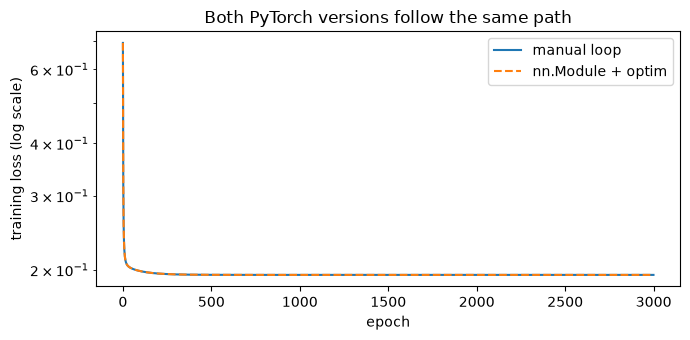

In [11]:
torch_model = LogisticRegressionModule(n_features)
with torch.no_grad():
    torch_model.linear.weight.zero_()
    torch_model.linear.bias.zero_()
optimizer = torch.optim.SGD(torch_model.parameters(), lr=BEST_LR)

module_history = []
for _ in range(EPOCHS):
    optimizer.zero_grad()
    logits = torch_model(Xtr_t)
    loss = bce(logits, ytr_t) + 0.5 * LAMBDA * (torch_model.linear.weight ** 2).sum()
    loss.backward()
    optimizer.step()
    module_history.append(loss.item())

plt.figure(figsize=(7, 3.5))
plt.plot(manual_history, label="manual loop")
plt.plot(module_history, "--", label="nn.Module + optim")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("training loss (log scale)")
plt.title("Both PyTorch versions follow the same path"); plt.legend(); plt.tight_layout(); plt.show()

## 9. Do the three implementations agree?

If they really are the same model, they should have (almost) the same coefficients and the same predictions. Small differences are expected because scikit-learn solves the problem exactly (L-BFGS solver) while the PyTorch versions take a fixed number of gradient steps and use 32 bit floats.

In [12]:
coef = pd.DataFrame({
    "sklearn": np.r_[sk_model.intercept_, sk_model.coef_.ravel()],
    "manual torch": np.r_[manual_params["b"].numpy(), manual_params["w"].numpy()],
    "nn.Module": np.r_[torch_model.linear.bias.detach().numpy(), torch_model.linear.weight.detach().numpy().ravel()],
}, index=["(intercept)"] + feature_names)

print("Largest absolute coefficient difference:")
print(f"  sklearn vs manual torch: {np.abs(coef['sklearn'] - coef['manual torch']).max():.5f}")
print(f"  manual torch vs nn.Module: {np.abs(coef['manual torch'] - coef['nn.Module']).max():.7f}")
print("\nCoefficients, sorted by size (positive = more likely to leave):")
print(coef.reindex(coef["sklearn"].abs().sort_values(ascending=False).index).round(3))

Largest absolute coefficient difference:
  sklearn vs manual torch: 0.00835
  manual torch vs nn.Module: 0.0000000

Coefficients, sorted by size (positive = more likely to leave):
                               sklearn  manual torch  nn.Module
(intercept)                     -3.117        -3.121     -3.121
log_host_listings               -0.432        -0.433     -0.433
superhost                       -0.316        -0.314     -0.314
district_EL PLA DEL REAL         0.267         0.259      0.259
host_tenure_months              -0.215        -0.214     -0.214
avail_30_share                   0.204         0.204      0.204
room_group_private               0.192         0.190      0.190
rating                          -0.181        -0.180     -0.180
has_license                     -0.176        -0.177     -0.177
listing_age_years               -0.170        -0.172     -0.172
room_group_entire               -0.154        -0.149     -0.149
shared_bath                      0.146         0.147

In [13]:
proba = {
    "val": {"baseline": baseline_val,
            "sklearn": sk_model.predict_proba(Xva)[:, 1],
            "manual torch": manual_predict_proba(manual_params, Xva),
            "nn.Module": torch_model.predict_proba(Xva)},
    "test": {"baseline": baseline_test,
             "sklearn": sk_model.predict_proba(Xte)[:, 1],
             "manual torch": manual_predict_proba(manual_params, Xte),
             "nn.Module": torch_model.predict_proba(Xte)},
}
print(f"Largest difference in test probabilities, sklearn vs manual torch: "
      f"{np.abs(proba['test']['sklearn'] - proba['test']['manual torch']).max():.5f}")

Largest difference in test probabilities, sklearn vs manual torch: 0.00275


## 10. Choosing the decision threshold (validation data only)

Every listing with a probability at or above the threshold gets a call. For each model, we try every threshold from 0.01 to 0.99 on the **validation** set and keep the one with the lowest total cost (see `business_cost` in `churn_model.py`).

There is also a simple rule of thumb to check against. A call is worth making when the expected saving is bigger than its cost: `p × SAVE_RATE × VALUE_LOST > CALL_COST`, so `p > CALL_COST / (SAVE_RATE × VALUE_LOST)`.

Break even probability: 0.182
sklearn: best validation threshold 0.18, cost €18,770
manual torch: best validation threshold 0.18, cost €18,770
nn.Module: best validation threshold 0.18, cost €18,770


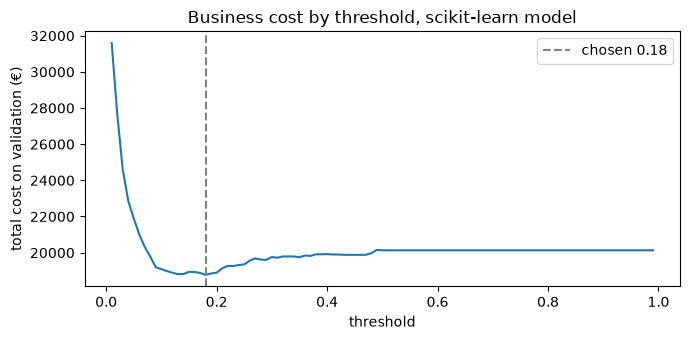

In [14]:
THRESHOLDS = np.round(np.arange(0.01, 1.0, 0.01), 2)
break_even = CALL_COST / (SAVE_RATE * VALUE_LOST)
print(f"Break even probability: {break_even:.3f}")

best_thresholds = {}
for name in ["sklearn", "manual torch", "nn.Module"]:
    costs = [business_cost(y_val, proba["val"][name], t) for t in THRESHOLDS]
    best_thresholds[name] = float(THRESHOLDS[int(np.argmin(costs))])
    print(f"{name}: best validation threshold {best_thresholds[name]:.2f}, cost €{min(costs):,.0f}")

plt.figure(figsize=(7, 3.5))
plt.plot(THRESHOLDS, [business_cost(y_val, proba["val"]["sklearn"], t) for t in THRESHOLDS])
plt.axvline(best_thresholds["sklearn"], ls="--", c="grey", label=f"chosen {best_thresholds['sklearn']:.2f}")
plt.xlabel("threshold"); plt.ylabel("total cost on validation (€)")
plt.title("Business cost by threshold, scikit-learn model"); plt.legend(); plt.tight_layout(); plt.show()

## 11. Final results on the test quarter (July → September)

This is the only time the test set is used. Each model is applied with the threshold it chose on validation. The baseline is shown as the two simple policies a team could follow without a model: call nobody, or call everyone.

In [15]:
rows = []
for name in ["baseline", "sklearn", "manual torch", "nn.Module"]:
    p = proba["test"][name]
    row = {"model": name, **evaluate(y_test, p)}
    if name == "baseline":
        row.update({"threshold": "call nobody", "hosts called": 0,
                    "leavers caught": 0, "cost (€)": business_cost(y_test, p, 1.01)})
        rows.append(row)
        rows.append({**row, "threshold": "call everyone", "hosts called": len(y_test),
                     "leavers caught": int(y_test.sum()), "cost (€)": business_cost(y_test, p, 0.0)})
        continue
    t = best_thresholds[name]
    called = p >= t
    row.update({"threshold": t, "hosts called": int(called.sum()),
                "leavers caught": int((called & (y_test == 1)).sum()),
                "cost (€)": business_cost(y_test, p, t)})
    rows.append(row)

results = pd.DataFrame(rows).set_index("model")
print(results.round(3).to_string())

t = best_thresholds["sklearn"]
cm = confusion_matrix(y_test, proba["test"]["sklearn"] >= t)
print(f"\nConfusion matrix, scikit-learn at threshold {t:.2f} (rows = actual stayed/left, columns = predicted stayed/left):")
print(cm)

              ROC AUC  PR AUC  log loss      threshold  hosts called  leavers caught  cost (€)
model                                                                                         
baseline        0.500   0.064     0.238    call nobody             0               0  116490.0
baseline        0.500   0.064     0.238  call everyone          5501             353  187680.0
sklearn         0.704   0.134     0.229           0.18           331              50  117610.0
manual torch    0.704   0.134     0.229           0.18           332              50  117630.0
nn.Module       0.704   0.134     0.229           0.18           332              50  117630.0

Confusion matrix, scikit-learn at threshold 0.18 (rows = actual stayed/left, columns = predicted stayed/left):
[[4867  281]
 [ 303   50]]


### Validation vs test: why the time split mattered

The validation set comes from the same quarter the model learned from. The test set is the next quarter. Comparing the two shows how much a random split would have flattered the model.

In [16]:
val_auc = roc_auc_score(y_val, proba["val"]["sklearn"])
test_auc = roc_auc_score(y_test, proba["test"]["sklearn"])
print(f"ROC AUC on validation (same quarter as training): {val_auc:.3f}")
print(f"ROC AUC on test (next quarter):                  {test_auc:.3f}")
gap = results.loc["sklearn", "cost (€)"] - results.loc["baseline", "cost (€)"].min()
print(f"Test cost of the sklearn model minus the cheapest simple policy: €{gap:,.0f}")

ROC AUC on validation (same quarter as training): 0.845
ROC AUC on test (next quarter):                  0.704
Test cost of the sklearn model minus the cheapest simple policy: €1,120


## 12. Did the feature engineering help?

An honest check: the same scikit-learn model trained only on the numeric columns that come ready to use in the raw file (no parsing, no new features, no categories), compared on the same validation set.

In [17]:
RAW_COLS = ["accommodates", "bedrooms", "availability_30", "availability_365", "estimated_occupancy_l365d",
            "number_of_reviews", "number_of_reviews_ltm", "review_scores_rating",
            "calculated_host_listings_count", "minimum_nights", "latitude", "longitude"]
raw_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("model", LogisticRegression(C=BEST_C, max_iter=5000))])
raw_train = train_period.loc[X_train.index, RAW_COLS]
raw_val = train_period.loc[X_val.index, RAW_COLS]
raw_pipe.fit(raw_train, y_train)

ablation = pd.DataFrame([
    {"features": "raw columns only", **evaluate(y_val, raw_pipe.predict_proba(raw_val)[:, 1])},
    {"features": "engineered", **evaluate(y_val, proba["val"]["sklearn"])},
]).set_index("features")
print(ablation.round(4))

                  ROC AUC  PR AUC  log loss
features                                   
raw columns only   0.7862  0.2443    0.2001
engineered         0.8450  0.2895    0.1827


## 13. Save everything the dashboard needs

The dashboard only **loads** these files. It never fits anything.

In [18]:
joblib.dump(preprocessor, MODELS / "preprocessor.joblib")
joblib.dump(sk_model, MODELS / "sklearn_logreg.joblib")
torch.save(manual_params, MODELS / "torch_manual.pt")
torch.save(torch_model.state_dict(), MODELS / "torch_module.pt")

# Engineered features and labels for both periods (for the distribution plots),
# plus the preprocessed matrices the models were scored on.
X_test.assign(left=y_test).to_csv(ARTIFACTS / "test_features.csv", index=False)
X_train_full.assign(left=y_train_full).to_csv(ARTIFACTS / "train_features.csv", index=False)
np.save(ARTIFACTS / "X_test.npy", Xte)
np.save(ARTIFACTS / "X_val.npy", Xva)
np.save(ARTIFACTS / "y_val.npy", y_val)

meta = {
    "feature_names": feature_names,
    "numeric_features": NUMERIC,
    "categorical_features": CATEGORICAL,
    "best_C": BEST_C,
    "best_lr": BEST_LR,
    "epochs": EPOCHS,
    "base_rate": float(base_rate),
    "best_thresholds": best_thresholds,
    "break_even": break_even,
    "results": results.reset_index().to_dict(orient="records"),
    "coefficients": coef.reset_index(names="feature").to_dict(orient="records"),
    "loss_history": {"manual torch": manual_history[::10], "nn.Module": module_history[::10]},
}
(ARTIFACTS / "metadata.json").write_text(json.dumps(meta, indent=2, default=float))
print("Saved:", sorted(p.name for p in MODELS.iterdir()), sorted(p.name for p in ARTIFACTS.iterdir()))

Saved: ['preprocessor.joblib', 'sklearn_logreg.joblib', 'torch_manual.pt', 'torch_module.pt'] ['X_test.npy', 'X_val.npy', 'metadata.json', 'test_features.csv', 'train_features.csv', 'y_val.npy']
